In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers

import time

import numpy as np
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

keras.utils.set_random_seed(2)

path_to_image_folders = Path("./datasets/dinnerware/")  # contains train/, validation/, test/
class_names = ["bowl", "glass", "mug", "plate"]

def load_split(split_name, shuffle):
    ds = keras.utils.image_dataset_from_directory(
        path_to_image_folders / split_name,
        class_names=class_names,
        image_size=(224, 224),
        batch_size=32,
        shuffle=shuffle,
        seed=0,
    )
    x_list, y_list = [], []
    for images, labels in ds:              # one loop, so images and labels stay paired
        x_list.append(images.numpy())
        y_list.append(labels.numpy())
    x = np.concatenate(x_list).astype("uint8")   # (N, 224, 224, 3), values 0–255
    y = np.concatenate(y_list).reshape(-1, 1)    # (N, 1)
    return x, y

x_train, y_train = load_split("train", shuffle=True)
x_val, y_val = load_split("validation", shuffle=False)
x_test, y_test = load_split("test", shuffle=False)

Found 313 files belonging to 4 classes.
Found 65 files belonging to 4 classes.
Found 71 files belonging to 4 classes.


In [3]:
print(x_train.shape, y_train.shape)
print(x_val.shape, y_val.shape)
print(x_test.shape, y_test.shape)
print(class_names)

(313, 224, 224, 3) (313, 1)
(65, 224, 224, 3) (65, 1)
(71, 224, 224, 3) (71, 1)
['bowl', 'glass', 'mug', 'plate']


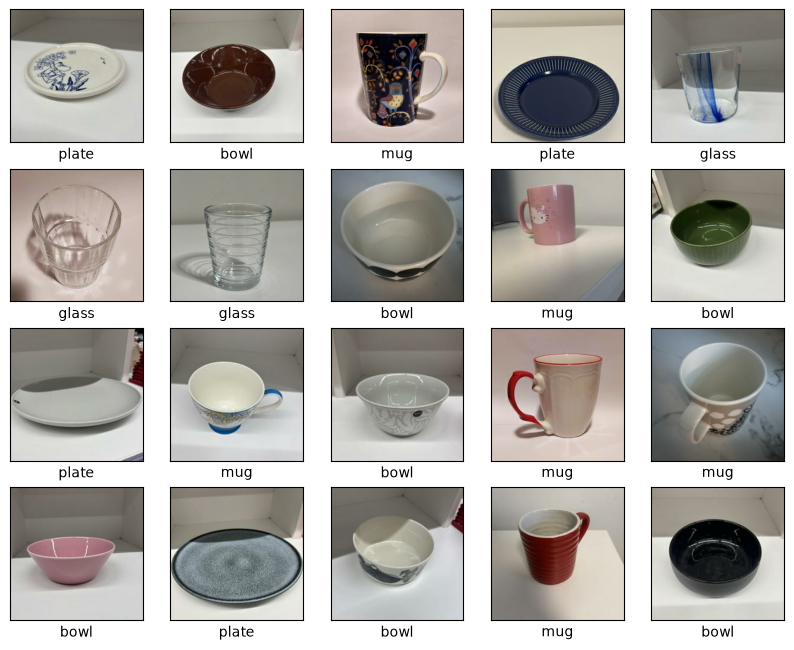

In [4]:
plt.figure(figsize=(10,10))
for i in range(20):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    # The CIFAR labels happen to be arrays, 
    # which is why need the extra index
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

In [5]:
x_train = x_train.astype("float32") / 255
x_val = x_val.astype("float32") / 255
x_test = x_test.astype("float32") / 255

In [6]:
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),

    #layers.RandomFlip("horizontal"),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    #layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       346,116 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 439,364 (1.68 MB)

 Trainable params: 439,364 (1.68 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [8]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)

t0 = time.time()

history = model.fit(x_train, y_train, epochs=50, batch_size=64, validation_data=(x_val, y_val), callbacks=[callback])

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 609ms/step - accuracy: 0.3195 - loss: 1.6765 - val_accuracy: 0.2308 - val_loss: 1.3829
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 596ms/step - accuracy: 0.3546 - loss: 1.3151 - val_accuracy: 0.5231 - val_loss: 1.2682
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 615ms/step - accuracy: 0.5144 - loss: 1.1800 - val_accuracy: 0.5385 - val_loss: 1.0804
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 617ms/step - accuracy: 0.5591 - loss: 1.0069 - val_accuracy: 0.5385 - val_loss: 1.0138
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 628ms/step - accuracy: 0.6550 - loss: 0.8771 - val_accuracy: 0.6154 - val_loss: 0.9555
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 642ms/step - accuracy: 0.6901 - loss: 0.7194 - val_accuracy: 0.5385 - val_loss: 1.0543
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 683ms/step - accuracy: 0.7508 - loss: 0.6039 - val_accuracy: 0.5846 - val_loss: 1.0038
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 652ms/step - accuracy: 0.8115 - loss: 0.4946 - val_accuracy: 0.6769 - val_loss:

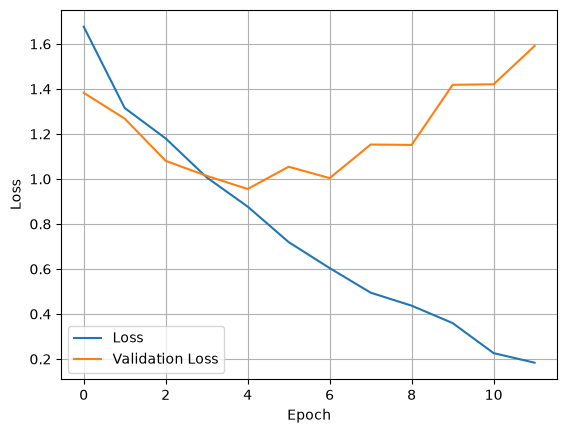

In [9]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

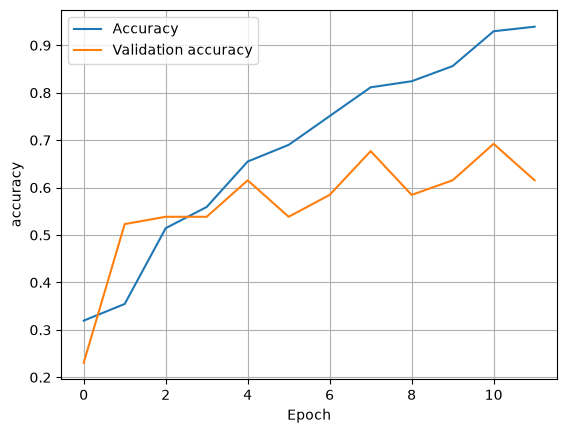

In [10]:
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.grid()
plt.show()

In [11]:
test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

3/3 - 0s - 81ms/step - accuracy: 0.6479 - loss: 0.8307
Test loss: 0.8307284116744995
Test accuracy: 0.6478873491287231


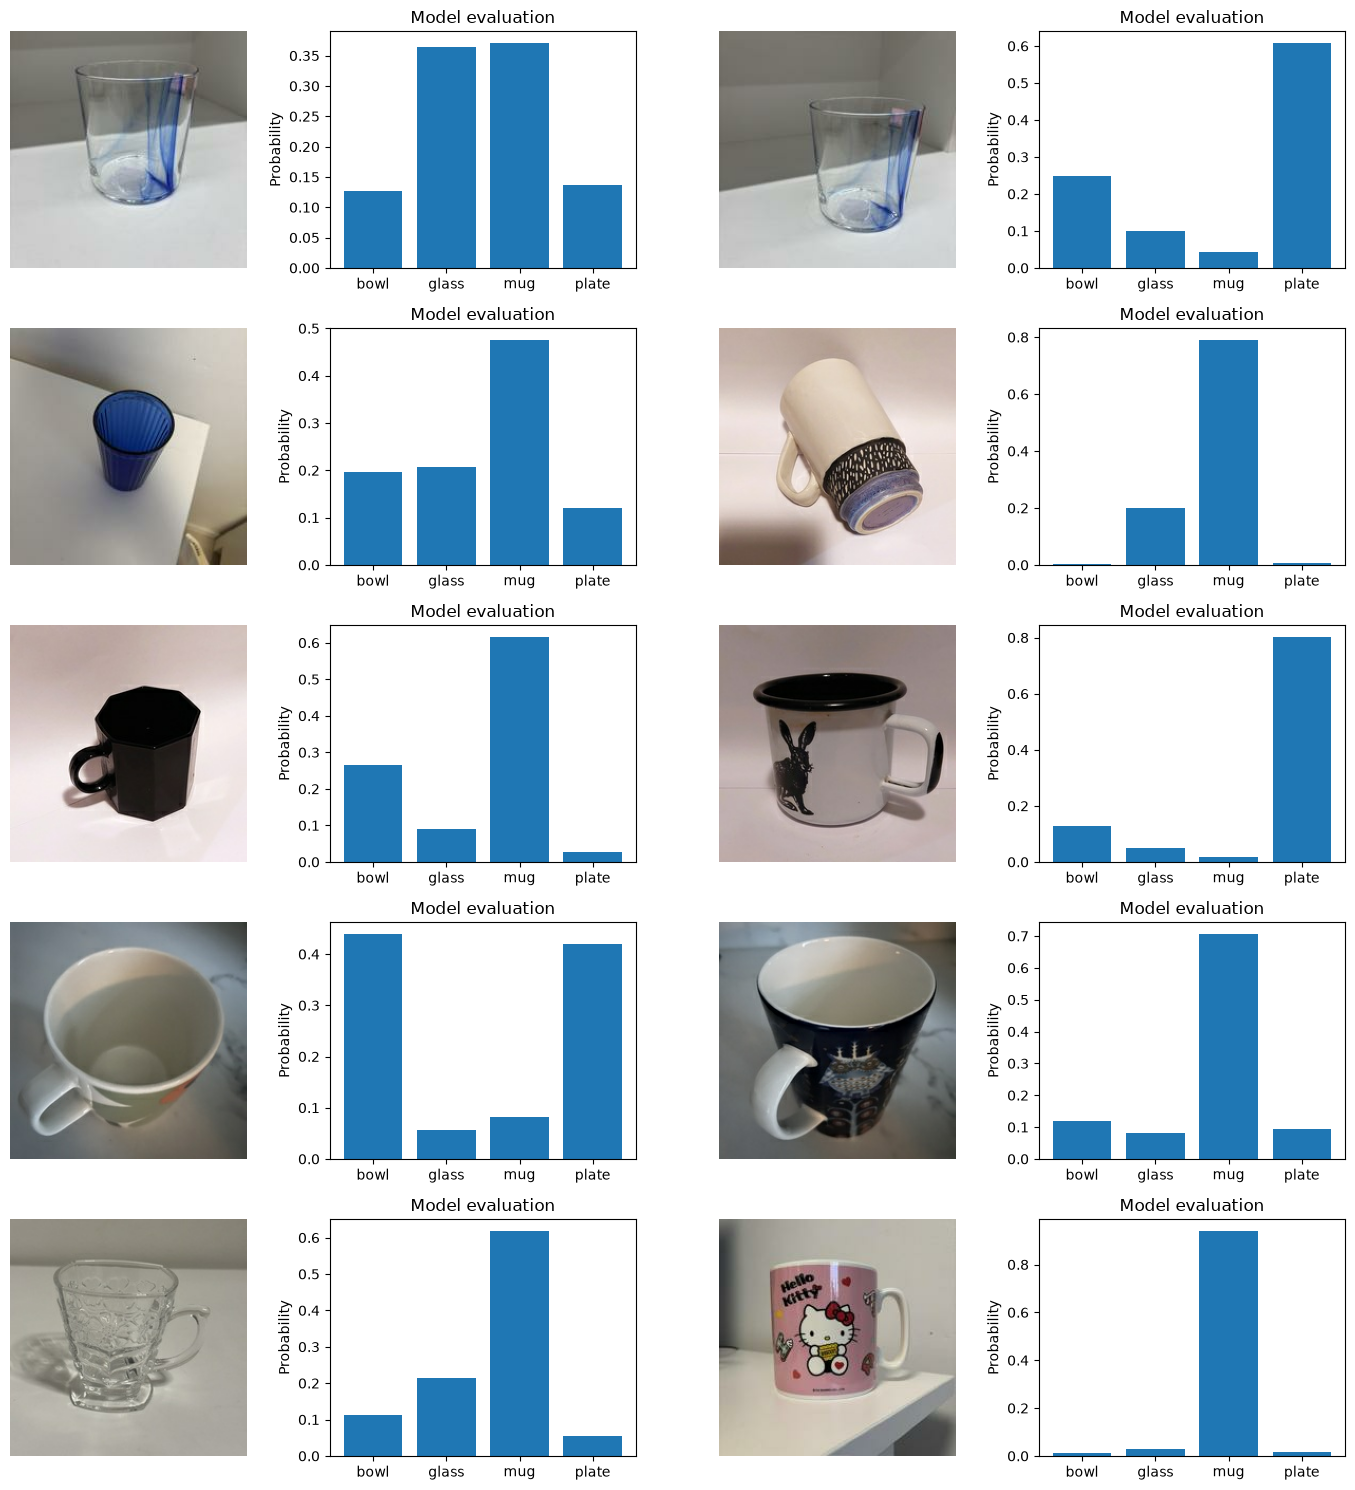

In [21]:
x = x_test
y = model(x)
start = 30

images_n = 10 #len(x_test)  # even number
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[start + k])
    plt.axis("off")

    plt.subplot(rows, 4, 2 * k + 2)
    plt.bar(class_names, y[start + k].numpy().flatten())
    plt.ylabel("Probability")
    plt.title("Model evaluation")

plt.tight_layout()
plt.show()

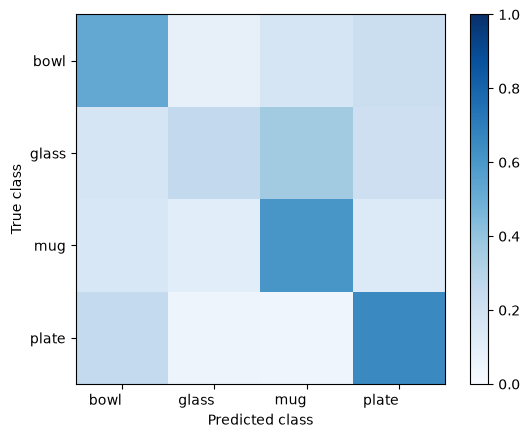

In [13]:
class_names_n = len(class_names)

probs = model.predict(x_test, verbose=0)
y_true = y_test.flatten()
mean_probs = [probs[y_true == c].mean(axis=0) for c in range(class_names_n)]

plt.imshow(mean_probs, cmap="Blues", vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(class_names_n), class_names, ha="right")
plt.yticks(range(class_names_n), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.show()